# Rescue drone mission II: backward smoothing for refining trajectory estimates near a rocky shoreline.

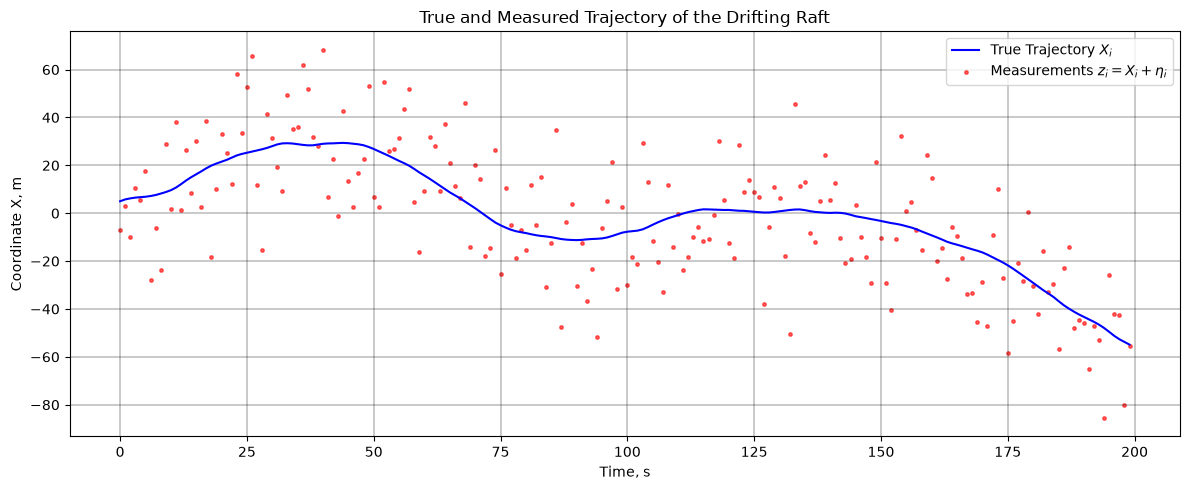

In [1]:
import numpy as np
from matplotlib import pyplot as plt

# define the constants to model the trajectory of the drifting raft
POINTS = 200
INIT_COORD = 5
INIT_VELOCITY = 1
T = 1

VARIANCE_A = 0.2**2
SIGMA_A = np.sqrt(VARIANCE_A)

VARIANCE_ETA = 20**2
SIGMA_ETA = np.sqrt(VARIANCE_ETA)

# a function to generate the true trajectory
def generate_true_trajectory(size, init_coord, init_velocity, sigma_a, t):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity

    for i in range(1, size):
        acceleration = np.random.normal(loc=0.0, scale=sigma_a)
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t

    return traj_points, velocity_points

# a function to generate measured trajectory points based on the true trajectory
def generate_measured_trajectory(true_trajectory, sigma_eta):
    measured_trajectory = true_trajectory.copy()
    return measured_trajectory + np.random.normal(0.0, sigma_eta, size=measured_trajectory.size)

# generate the trajectories 
true_trajectory_raft, true_velocity_raft = generate_true_trajectory(POINTS, INIT_COORD, INIT_VELOCITY, SIGMA_A, T)
measured_trajectory_raft = generate_measured_trajectory(true_trajectory_raft, SIGMA_ETA)

np.savetxt("true_trajectory_raft.txt", true_trajectory_raft)
np.savetxt("true_velocity_raft.txt", true_velocity_raft)
np.savetxt("measured_trajectory_raft.txt", measured_trajectory_raft)

# plot the true trajectory and the measured points
steps = np.arange(true_trajectory_raft.size * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_raft, color="blue", linewidth=1.5, label="True Trajectory $X_i$")
ax.scatter(steps, measured_trajectory_raft, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
ax.set_title("True and Measured Trajectory of the Drifting Raft")
ax.set_xlabel("Time, s")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()
